# 10. Modelos y benchmark de demanda

Se comparan MLP, LSTM y CNN1D como familias de aprendizaje profundo, con ARX regularizado y referencias estacionales como controles. Cada configuración se evalúa con cinco inicializaciones sobre los mismos 1.461 orígenes diarios de 2022–2025. La selección utiliza el MASE de validación; el análisis presenta resultados descriptivos y su variabilidad por inicialización y por fecha.

In [1]:
from pathlib import Path
import json,hashlib,itertools
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'results/jbook/modelos_actualizados.json').exists())
procedencia=json.loads((ROOT/'results/jbook/modelos_actualizados.json').read_text(encoding='utf-8'))
SHA=procedencia['commit'];SNAP=ROOT/'results/repositorio'/SHA
C=SNAP/'results/consolidado';OUT=ROOT/'results/jbook/modelos_actuales';OUT.mkdir(parents=True,exist_ok=True)
registro=json.loads((C/'modelos.json').read_text(encoding='utf-8'))
modelos=['mlp','arx_lineal','cnn1d','lstm'];neuronales=['mlp','cnn1d','lstm']
etiquetas={'mlp':'MLP','arx_lineal':'ARX','cnn1d':'CNN1D','lstm':'LSTM','ingenuo_24h':'Ingenuo diario','ingenuo_168h':'Ingenuo semanal'}
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
importacion=json.loads((SNAP/'IMPORTACION.json').read_text(encoding='utf-8'))
huellas={x['archivo']:x for x in importacion['archivos']}
indice=pd.read_csv(C/'indice_artefactos_v3_v4.csv')
assert len(indice)==2304 and not indice.archivo.duplicated().any()
for fila in indice.itertuples():
    p=SNAP/fila.archivo
    assert p.stat().st_size==fila.bytes
    assert hashlib.sha256(p.read_bytes()).hexdigest()==fila.sha256==huellas[fila.archivo]['sha256']
runs=[];pilotos=[];confirmaciones=[];filtros=[];pred={};carpetas={};escaladores={};historias={};y=None;origen=None
for nombre in modelos:
    r=registro[nombre];carpeta=SNAP/'results'/r['ejecucion']
    seleccion=r['configuracion']['id']
    pp=pd.read_csv(carpeta/'piloto.csv');pp=pp.loc[(pp.modelo==nombre)&(pp.configuracion==seleccion)]
    assert len(pp)==20 and not pp.duplicated(['semilla','fold']).any()
    pilotos.append(pp)
    pila=[]
    for a in sorted(r['artefactos'],key=lambda a:a['semilla']):
        met=json.loads((SNAP/a['metricas']).read_text(encoding='utf-8'))
        esc=json.loads((SNAP/a['escaladores']).read_text(encoding='utf-8'))
        historia=pd.DataFrame(json.loads((SNAP/a['historial']).read_text(encoding='utf-8')))
        assert met['semilla']==a['semilla'] and met['params']==r['configuracion']['params']
        assert met['configuracion']==seleccion and len(historia)==met['epocas']
        assert historia.epoca.tolist()==list(range(1,len(historia)+1))
        assert met['mejor_epoca']==int(historia.val_loss.idxmin()+1)
        assert pd.Timestamp(esc['fin_ajuste'])<pd.Timestamp('2022-01-01',tz='America/Bogota')
        with np.load(SNAP/a['predicciones'],allow_pickle=False) as z:
            if y is None:y=z['y'].astype(float);origen=z['origen'].copy()
            assert np.array_equal(y,z['y']) and np.array_equal(origen,z['origen'])
            assert z['yhat'].shape==y.shape and np.isfinite(z['yhat']).all()
            pila.append(z['yhat'].astype(float))
        runs.append(met);historias[(nombre,a['semilla'])]=historia
        carpetas[(nombre,a['semilla'])]=SNAP/a['pesos']
        escaladores[(nombre,a['semilla'])]=esc
    pred[nombre]=np.stack(pila)
piloto=pd.concat(pilotos,ignore_index=True);runs=pd.DataFrame(runs)
assert len(runs)==20 and not runs.duplicated(['modelo','semilla']).any()
assert all(set(d.semilla)==set(range(1000,1005)) for _,d in runs.groupby('modelo'))
fechas=pd.to_datetime(origen,unit='ns',utc=True).tz_convert('America/Bogota')
assert fechas.equals(pd.date_range('2022-01-01','2025-12-31',freq='D',tz='America/Bogota'))
assert y.shape==(1461,24) and np.isfinite(y).all()
escala=float(escaladores[('mlp',1000)]['escala_mase'])
loss_h={};loss_d={};residuos={};calculadas=[]
for nombre in modelos:
    errores=pred[nombre]-y[None,:,:]
    loss_h[nombre]=np.abs(errores).mean(axis=0)/escala
    loss_d[nombre]=loss_h[nombre].mean(axis=1)
    residuos[nombre]=errores[0]
    for j,semilla in enumerate(range(1000,1005)):
        e=errores[j];mae=np.abs(e).mean();rmse=np.sqrt(np.mean(e**2))
        m=dict(modelo=nombre,semilla=semilla,MASE=mae/escala,MAE=mae,RMSE=rmse,R2=1-np.mean(e**2)/np.var(y),sesgo=e.mean(),sMAPE=(200*np.abs(e)/(np.abs(pred[nombre][j])+np.abs(y))).mean())
        original=runs.loc[(runs.modelo==nombre)&(runs.semilla==semilla)].iloc[0]
        assert np.allclose([m[k] for k in ['MASE','MAE','RMSE','sMAPE']],[original[k] for k in ['MASE','MAE','RMSE','sMAPE']],rtol=2e-6)
        calculadas.append(m)
calculadas=pd.DataFrame(calculadas)
seleccion_publicada=pd.read_csv(C/'modelos_seleccionados.csv').set_index('modelo')
assert np.allclose(calculadas.groupby('modelo').MASE.mean().sort_index(),seleccion_publicada.MASE_prueba.sort_index())
referencias=json.loads((C/'referencias_test.json').read_text(encoding='utf-8'))
filas=[]
for nombre in modelos:
    d=calculadas.loc[calculadas.modelo==nombre];media=d.MASE.mean();sd=d.MASE.std(ddof=1);ancho=stats.t.ppf(.975,len(d)-1)*sd/np.sqrt(len(d))
    filas.append(dict(familia=nombre,Modelo=etiquetas[nombre],n=len(d),MASE=media,DE=sd,IC95_inf=media-ancho,IC95_sup=media+ancho,MAE_kWh=d.MAE.mean(),RMSE_kWh=d.RMSE.mean(),sMAPE_pct=d.sMAPE.mean(),R2=d.R2.mean(),sesgo_kWh=d.sesgo.mean(),parametros=int(runs.loc[runs.modelo==nombre,'n_parametros'].iloc[0]),ajuste_s=float(runs.loc[runs.modelo==nombre,'segundos'].median())))
for nombre,m in referencias.items():
    filas.append(dict(familia=nombre,Modelo=etiquetas[nombre],n=1,MASE=m['MASE'],DE=np.nan,IC95_inf=np.nan,IC95_sup=np.nan,MAE_kWh=m['MAE'],RMSE_kWh=m['RMSE'],sMAPE_pct=m['sMAPE'],R2=1-m['RMSE']**2/np.var(y),sesgo_kWh=np.nan,parametros=0,ajuste_s=np.nan))
benchmark=pd.DataFrame(filas).sort_values('MASE').reset_index(drop=True);benchmark.insert(0,'rango',np.arange(1,len(benchmark)+1))
benchmark.to_csv(OUT/'benchmark.csv',index=False);benchmark.to_csv(ROOT/'book/benchmark_modelos.csv',index=False)
calculadas.to_csv(OUT/'metricas_desde_predicciones.csv',index=False)
for fase,destino in [('filtro',filtros),('confirmacion',confirmaciones)]:
    for ruta in sorted(set(r['ejecucion'] for r in registro.values())):
        destino.append(pd.read_csv(SNAP/'results'/ruta/(fase+'.csv')))
filtro=pd.concat(filtros,ignore_index=True);confirmacion=pd.concat(confirmaciones,ignore_index=True)
assert len(filtro)==90 and len(confirmacion)==144
mejor=benchmark.loc[benchmark.familia=='mlp'].iloc[0]
reduccion_semanal=100*(1-mejor.MASE/referencias['ingenuo_168h']['MASE'])
mae_mlp=float(mejor.MAE_kWh);mase_mlp=float(mejor.MASE)

formato_p=lambda x: "<1e-300" if x==0 else f"{x:.3g}"


Las predicciones reconstruyen las métricas registradas para las 20 realizaciones seleccionadas. La escala fija de MASE es 215,617.90 kWh, calculada con diferencias semanales de 2000–2017. Se verifican las huellas de 2.304 artefactos, incluidas las alternativas de búsqueda; las 20 realizaciones del benchmark corresponden a las cuatro configuraciones seleccionadas.

## 10.1. Entradas, escalado y partición

El origen diario de las 00:00 genera 24 pronósticos horarios. La historia contiene 168 horas de demanda disponible y 23 variables de calendario. MLP utiliza demanda histórica y calendario futuro aplanados; ARX conserva 48 rezagos; LSTM y CNN1D concatenan calendario histórico a la demanda y calendario futuro a la representación temporal. Las condiciones meteorológicas, hidrología y noticias caracterizadas en el EDA no forman parte de estas entradas.

Las etiquetas y la demanda histórica se normalizan por el nivel medio conocido en la ventana. En las redes secuenciales, la demanda normalizada se centra en uno y se divide por su desviación estimada en entrenamiento. Los escaladores del calendario y las representaciones tabulares se ajustan con el tramo de optimización de cada pliegue; la parada interna y el año externo quedan separados. Las salidas se restituyen a kWh mediante el nivel del origen.

La validación expansiva comprende 2018–2021. El último 10 % del historial previo se reserva para parada temprana y se comprueba la separación de las 24 etiquetas entre tramos. El ajuste final utiliza el historial anterior a 2022 con la misma reserva interna. MASE conserva un denominador fijo de referencia para hacer comparables los errores entre pliegues; ese denominador no se utiliza para optimizar las redes.

## 10.2. Arquitecturas y configuraciones

| Modelo | Representación seleccionada | Tasa de aprendizaje | Dropout | Regularización | Lote | Pérdida |
|---|---|---|---|---|---|---|
| MLP | 2 capas de 128 unidades | 0.0046896 | 0.0035459 | 0.00038272 | 64 | huber |
| LSTM | 1 capa de 48 unidades | 0.001 | 0.1 | 0.0001 | 256 | huber |
| CNN1D | 1 convolución, 16 filtros, kernel 5 | 0.0003 | 0.1 | 0.0001 | 256 | huber |
| ARX | lasso, 48 rezagos | 0.00065826 | 0 | 1.3734e-07 | 64 | mae |

La MLP aplica dos transformaciones densas ReLU y una salida directa de 24 valores. La LSTM utiliza el último estado oculto; la CNN1D aplica convolución, ReLU, Dropout1d, promedio local de factor dos y aplanamiento. Las dos redes secuenciales concatenan el calendario futuro antes de la salida lineal y aprenden una desviación alrededor de uno en la escala del nivel. ARX penaliza los coeficientes mediante lasso.

Para MLP, con z como vector de entrada, la predicción es g(z)=W₃ ReLU(W₂ ReLU(W₁z+b₁)+b₂)+b₃. Para LSTM, hₜ,cₜ=LSTM([xₜ,kₜ],hₜ₋₁,cₜ₋₁), y la salida normalizada es 1+W[hₗ,k_f]+b. En CNN1D, z=flatten(pool₂(ReLU(Convₖ([x,k_p])))) y la salida es 1+W[z,k_f]+b. El Dropout se activa durante el ajuste y se desactiva al evaluar.

Con L=168, H=24, K=23 y f=24, el costo dominante por ejemplo es O(du+u²+uH) para MLP, O(Lu(f+u)+(u+HK)H) para LSTM y O(Lkfc+(Lc/2+HK)H) para CNN1D. Los parámetros se verifican frente a los metadatos guardados; capacidad, tiempo de ajuste y latencia de inferencia son magnitudes distintas.

In [2]:
L,H,K,f=168,24,23,24;d=L+H*K;u=128
conteos={'mlp':(d+1)*u+(u+1)*u+(u+1)*H,'lstm':4*48*(f+48+2)+(48+H*K+1)*H,'cnn1d':(5*f+1)*16+((L//2)*16+H*K+1)*H,'arx_lineal':(48+H*K+1)*H}
assert all(int(runs.loc[runs.modelo==m,'n_parametros'].iloc[0])==n for m,n in conteos.items())


La MLP concentra la mayor cantidad de parámetros y la LSTM requiere más tiempo de ajuste en el dispositivo registrado. La CNN1D posee una cabeza densa sobre posiciones temporales agrupadas; menos filtros no implica necesariamente menos parámetros que una LSTM con último estado. Estos costos describen el ajuste completo, incluida la evaluación registrada, y no miden latencia de inferencia.

## 10.3. Búsqueda, confirmación y piloto

Se examinaron 20 candidatos de MLP, 20 de ARX, 24 de LSTM y 26 de CNN1D. El filtro empleó el año 2019, semilla 42 y un máximo de 30 épocas; los finalistas se compararon en 2018–2021 con semillas 43 y 44 y un máximo de 60 épocas. La configuración de cada familia se eligió por el MASE medio de confirmación. El piloto conserva cinco semillas, 100–104, por año externo; prueba conserva 1000–1004. El número de candidatos es desigual y debe considerarse al comparar familias.

El optimizador es AdamW, con recorte de gradiente a uno y precisión completa. La parada exige al menos diez épocas, paciencia de seis y mejora mayor que max(10⁻⁶, 0,002 × pérdida de referencia). La paciencia y la restauración cumplen funciones distintas: se guarda el mínimo absoluto de pérdida, aunque sólo una mejora suficiente reinicia la paciencia. El planificador plateau reduce la tasa a la mitad tras dos épocas sin mejora. Huber utiliza κ=0,05 en la escala normalizada.

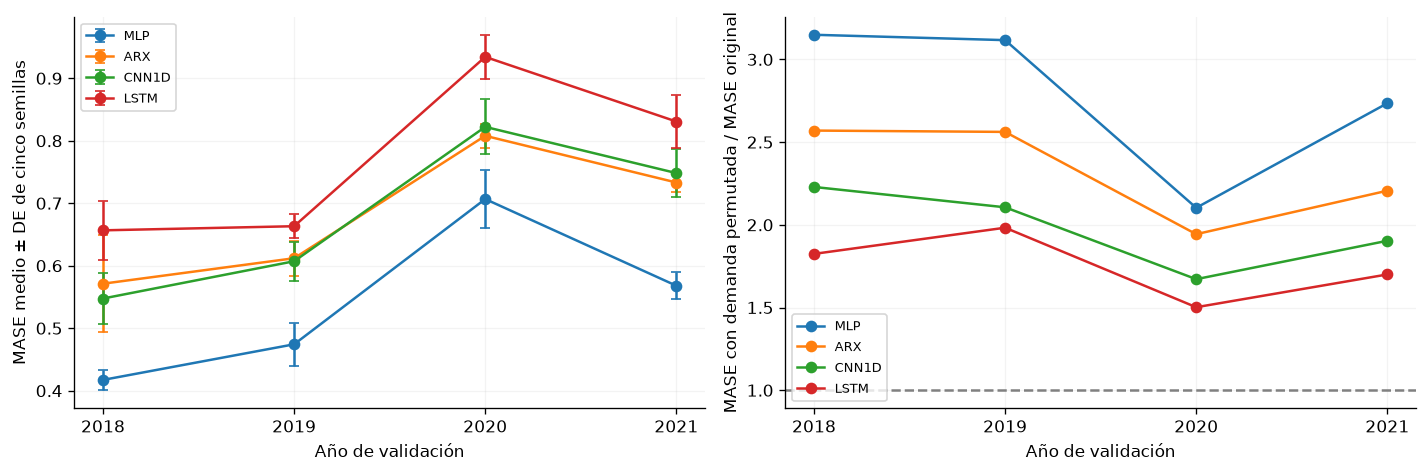

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for m in modelos:
    p=piloto.loc[piloto.modelo==m];grupo=p.groupby('fold').MASE
    axes[0].errorbar(grupo.mean().index,grupo.mean(),yerr=grupo.std(),marker='o',capsize=3,label=etiquetas[m])
    q=p.groupby('fold')[['MASE','MASE_demanda_permutada']].mean()
    axes[1].plot(q.index,q.MASE_demanda_permutada/q.MASE,marker='o',label=etiquetas[m])
axes[0].set(xticks=[2018,2019,2020,2021],xlabel='Año de validación',ylabel='MASE medio ± DE de cinco semillas')
axes[1].axhline(1,color='grey',ls='--');axes[1].set(xticks=[2018,2019,2020,2021],xlabel='Año de validación',ylabel='MASE con demanda permutada / MASE original')
for ax in axes:ax.legend(fontsize=8)
fig.tight_layout();display(fig);plt.close(fig)
peor_piloto=etiquetas[piloto.groupby('modelo').MASE.mean().idxmax()]
razon_permutacion=piloto.groupby('modelo')[['MASE','MASE_demanda_permutada']].mean().eval('MASE_demanda_permutada/MASE')


La validación muestra diferencias entre años y sitúa a LSTM como la familia de mayor MASE medio del piloto. La permutación intercambia la trayectoria de demanda entre orígenes y conserva el nivel y calendario del ejemplo: el aumento de error mide sensibilidad condicional a esa trayectoria, no el aporte total de la demanda ni una ablación causal.

### Piloto y dimensionamiento

La media por semilla agrega los cuatro años externos antes de estimar dispersión. Los 20 resultados semilla–año no se consideran 20 inicializaciones independientes. Se conserva δ relativo=0,03. Las diferencias de MASE y su DE se expresan respecto al MASE medio piloto de MLP; esta conversión usa únicamente validación y no fija un margen absoluto adicional. Para cada diferencia pareada se calcula R≈[(z₀,₉₇₅+z₀,₈)σ̂d/δ]², δ/σ̂d y la diferencia mínima detectable con cinco semillas. Se añade planificación conservadora con Bonferroni para tres comparaciones.

In [4]:
# Una realización piloto es la media de sus cuatro años externos.
piloto_semillas=piloto.groupby(['modelo','semilla']).MASE.mean().unstack('modelo').reindex(columns=modelos)
assert piloto_semillas.shape==(5,4)
resumen_piloto=piloto_semillas.agg(['mean','std']).T.rename(columns={'mean':'MASE_media','std':'DE'})
resumen_piloto['CV_pct']=100*resumen_piloto.DE/resumen_piloto.MASE_media
resumen_piloto['n_semillas']=5
display(resumen_piloto.rename(index=etiquetas).round(5))
resumen_piloto.to_csv(OUT/'piloto_resumen.csv')
piloto.groupby(['modelo','fold']).MASE.agg(['mean','std','count']).to_csv(OUT/'piloto_por_fold.csv')
delta_rel=.03;referencia_piloto=float(resumen_piloto.loc['mlp','MASE_media'])
z=stats.norm.ppf(.975)+stats.norm.ppf(.8)
z_familia=stats.norm.ppf(1-.05/(2*3))+stats.norm.ppf(.8)
dimension=[]
for a,b in itertools.combinations(neuronales,2):
    d=(piloto_semillas[a]-piloto_semillas[b])/referencia_piloto;sd=float(d.std(ddof=1))
    dimension.append(dict(comparacion=etiquetas[a]+' − '+etiquetas[b],sigma_d_rel=sd,delta_rel=delta_rel,delta_sobre_sigma=delta_rel/sd,
        R_normal=max(5,int(np.ceil((z*sd/delta_rel)**2))),R_Bonferroni=max(5,int(np.ceil((z_familia*sd/delta_rel)**2))),
        MDD_5_rel=z*sd/np.sqrt(5),MDD_5_pct_MLP=100*z*sd/np.sqrt(5)))
dimension=pd.DataFrame(dimension);display(dimension.round(5));dimension.to_csv(OUT/'dimensionamiento_piloto.csv',index=False)
R_max=int(dimension.R_normal.max());R_familia=int(dimension.R_Bonferroni.max())


,MASE_media,DE,CV_pct,n_semillas
modelo,,,,
MLP,0.54156,0.01664,3.07261,5
ARX,0.68109,0.01652,2.42527,5
CNN1D,0.68130,0.03233,4.74531,5
LSTM,0.77122,0.01833,2.37696,5


,comparacion,sigma_d_rel,delta_rel,delta_sobre_sigma,R_normal,R_Bonferroni,MDD_5_rel,MDD_5_pct_MLP
0,MLP − CNN1D,0.07154,0.03,0.41937,45,60,0.08963,8.96270
1,MLP − LSTM,0.05334,0.03,0.56238,25,34,0.06684,6.68362
2,CNN1D − LSTM,0.06744,0.03,0.44483,40,53,0.08450,8.44976


El máximo requerido para el margen relativo del 3 % por la aproximación normal individual es 45 semillas y asciende a 60 con Bonferroni. Son estimaciones sensibles a cinco diferencias piloto y no una garantía de potencia. Si R supera las cinco realizaciones ejecutadas, el diseño no acredita potencia del 80 % para ese contraste. [Resumen piloto](_static/resultados/piloto_resumen.csv), [detalle por año](_static/resultados/piloto_por_fold.csv) y [dimensionamiento](_static/resultados/dimensionamiento_piloto.csv).

## 10.4. Curvas de aprendizaje

Se presentan pérdidas de ajuste y parada interna para la semilla 1000. Las funciones MAE y Huber se interpretan dentro de cada panel; su magnitud no constituye un ranking entre familias. El Dropout activo durante el ajuste también influye en la separación visual entre curvas.

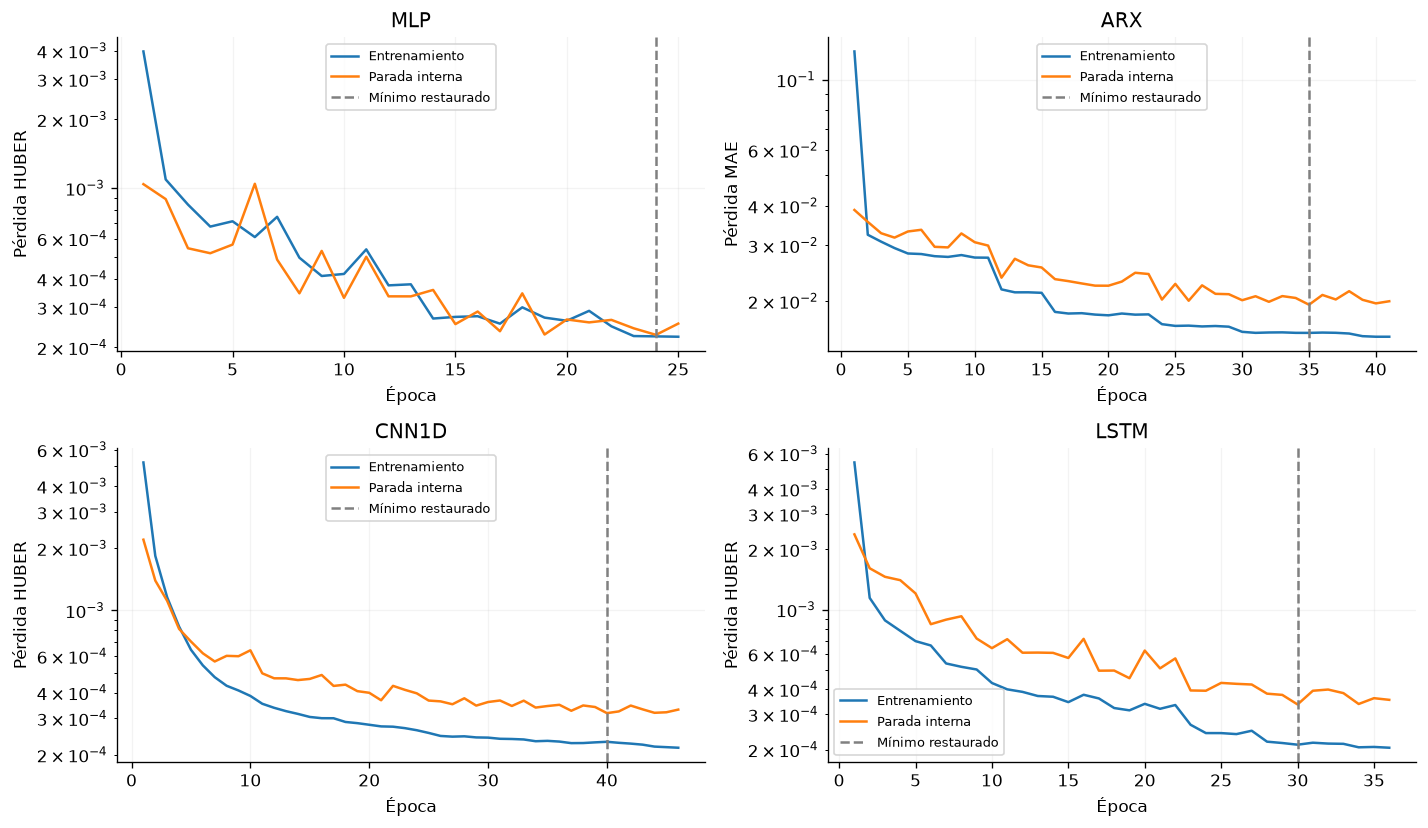

In [5]:
fig,axes=plt.subplots(2,2,figsize=(12,7));curvas=[]
for ax,m in zip(axes.ravel(),modelos):
    h=historias[(m,1000)];r=runs.loc[(runs.modelo==m)&(runs.semilla==1000)].iloc[0]
    ax.plot(h.epoca,h.train_loss,label='Entrenamiento');ax.plot(h.epoca,h.val_loss,label='Parada interna');ax.axvline(r.mejor_epoca,color='grey',ls='--',label='Mínimo restaurado')
    ax.set(title=etiquetas[m],xlabel='Época',ylabel='Pérdida '+r.params['perdida'].upper(),yscale='log');ax.legend(fontsize=8)
    curvas.append(h.assign(modelo=m,semilla=1000))
fig.tight_layout();display(fig);plt.close(fig)
pd.concat(curvas).to_csv(OUT/'curvas_aprendizaje_1000.csv',index=False)
epocas_min=int(runs.epocas.min());epocas_max=int(runs.epocas.max())

El descenso más pronunciado se concentra en las primeras épocas y después aparecen mejoras más pequeñas. Las realizaciones finales se detienen entre 19 y 48 épocas. La línea vertical identifica el mínimo restaurado, que puede preceder a la última época. La separación entre pérdidas no equivale por sí sola a una medida de sobreajuste; el error de evaluación se calcula con Dropout desactivado.

## 10.5. Benchmark de prueba

El ranking ordena el MASE medio de cinco realizaciones, no la mejor semilla. Los intervalos t del 95 % describen variación de inicialización condicionada a las fechas evaluadas; no representan incertidumbre temporal. Los dos ingenuos utilizan la misma disponibilidad histórica que los modelos.

La [comparación entre demanda observada y predicha](#observado-prediccion) permite contextualizar estos errores mediante todas las horas de prueba y el detalle de una semana.

La {ref}`importancia agrupada de variables <importancia-variables>` complementa el rendimiento global mediante la sensibilidad de los modelos a demanda y calendario.

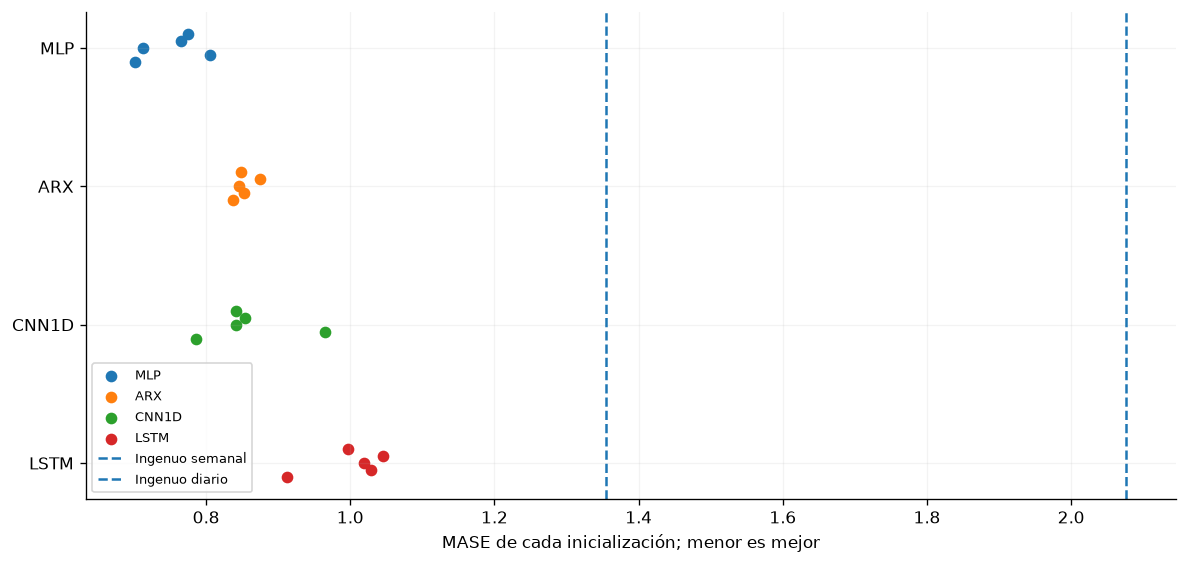

In [6]:
fig,ax=plt.subplots(figsize=(10,4.8))
for i,m in enumerate(modelos):
    v=calculadas.loc[calculadas.modelo==m].sort_values('semilla').MASE;ax.scatter(v,np.full(5,i)+np.linspace(-.1,.1,5),label=etiquetas[m])
for r in ['ingenuo_168h','ingenuo_24h']:ax.axvline(referencias[r]['MASE'],ls='--',label=etiquetas[r])
ax.set(yticks=range(4),yticklabels=[etiquetas[m] for m in modelos],xlabel='MASE de cada inicialización; menor es mejor');ax.invert_yaxis();ax.legend(fontsize=8);fig.tight_layout();display(fig);plt.close(fig)

La MLP presenta el menor error medio: MASE 0.752, equivalente a MAE 162,149 kWh y una reducción del 44.5 % frente al ingenuo semanal. ARX y CNN1D quedan próximos; LSTM presenta mayor error. Las cuatro familias mejoran las dos referencias estacionales en el agregado. La escala MASE fija explica que el ingenuo semanal de prueba no tenga necesariamente valor uno.

La figura muestra las cinco realizaciones individuales; la tabla presenta sus agregados, intervalos t95 % y métricas complementarias. [Benchmark completo](benchmark_modelos.csv). El costo se resume para el mismo equipo de ajuste; la latencia se mide por separado en CPU, con un origen y 24 salidas.

In [7]:
display(benchmark.set_index('Modelo')[['MASE','DE','IC95_inf','IC95_sup','MAE_kWh','RMSE_kWh','sMAPE_pct','R2']].round(5))
latencias=pd.read_csv(OUT/'latencia_inferencia.csv');costo=benchmark.loc[benchmark.familia.isin(modelos),['familia','Modelo','parametros','ajuste_s']].set_index('familia');costo=costo.join(latencias.groupby('modelo')[['mediana_ms','p95_ms']].median());display(costo.set_index('Modelo').round(4));costo.to_csv(OUT/'costo_modelos.csv')

,MASE,DE,IC95_inf,IC95_sup,MAE_kWh,RMSE_kWh,sMAPE_pct,R2
Modelo,,,,,,,,
MLP,0.75202,0.04378,0.69767,0.80638,162149.39329,209153.20808,1.76192,0.96713
ARX,0.85168,0.01444,0.83375,0.86960,183636.40615,245952.61178,2.00417,0.95462
CNN1D,0.85735,0.06543,0.77610,0.93859,184859.30629,238815.14519,2.03186,0.95706
LSTM,1.00050,0.05229,0.93557,1.06543,215726.18776,270164.35923,2.41719,0.94516
Ingenuo semanal,1.35491,NaN,NaN,NaN,292142.08711,444631.86974,3.21397,0.85174
Ingenuo diario,2.07672,NaN,NaN,NaN,447778.99357,659593.46159,4.97667,0.67372


,parametros,ajuste_s,mediana_ms,p95_ms
Modelo,,,,
MLP,111896,4.4547,0.0482,0.0608
ARX,14424,3.5340,0.0209,0.0265
CNN1D,47464,3.1139,0.0656,0.0905
LSTM,28632,14.3724,0.2858,0.6576


RMSE supera MAE al dar mayor peso a errores grandes; R² compara el error cuadrático con la dispersión del objetivo en todo el periodo. El sesgo firmado permite distinguir tendencia a sobreestimar o subestimar. La DE resume diferencias entre inicializaciones y no la variación diaria.

## 10.6. Validación y generalización

Se comparan el MASE de confirmación, el piloto de cinco semillas y el periodo de prueba con el mismo denominador. La confirmación participa en selección; el piloto describe estabilidad de la configuración elegida. Los periodos tienen años y regímenes diferentes.

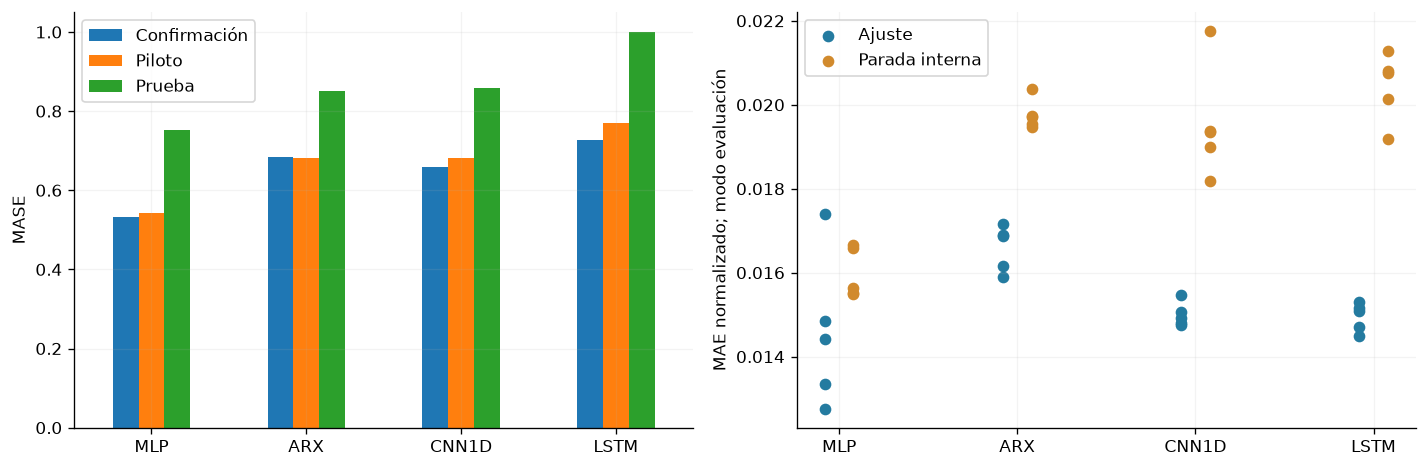

In [8]:
generalizacion=pd.DataFrame([{'modelo':m,'Confirmación':registro[m]['MASE_cv'],'Piloto':piloto.loc[piloto.modelo==m,'MASE'].mean(),'Prueba':calculadas.loc[calculadas.modelo==m,'MASE'].mean()} for m in modelos]).set_index('modelo')
generalizacion.index=generalizacion.index.map(etiquetas);fig,axes=plt.subplots(1,2,figsize=(12,4));generalizacion.plot.bar(ax=axes[0],rot=0);axes[0].set(ylabel='MASE',xlabel='')
for i,m in enumerate(modelos):
    d=runs.loc[runs.modelo==m];axes[1].scatter(np.full(len(d),i)-.08,d.MAE_train_normalizado_eval,label='Ajuste' if i==0 else None,color='#247ba0');axes[1].scatter(np.full(len(d),i)+.08,d.MAE_es_normalizado_eval,label='Parada interna' if i==0 else None,color='#d18a2d')
axes[1].set(xticks=range(4),xticklabels=[etiquetas[m] for m in modelos],ylabel='MAE normalizado; modo evaluación');axes[1].legend()
fig.tight_layout();display(fig);plt.close(fig)
brecha_mlp=100*(generalizacion.loc['MLP','Prueba']/generalizacion.loc['MLP','Piloto']-1)

El MASE de prueba de MLP supera al piloto un 38.9 %. El aumento es compatible con una generalización más difícil en un periodo posterior y no se interpreta como un efecto causal de una variable aislada. El panel derecho confirma mayor error en la reserva interna que en ajuste con Dropout desactivado; evita atribuir esa diferencia a modos de evaluación distintos.

(observado-prediccion)=
## 10.7. Demanda observada frente a predicción

La comparación reúne las 35.064 horas de prueba de 2022–2025 y las cinco inicializaciones de cada familia. Cada panel representa la densidad de pares observado–predicho; la diagonal indica una predicción exacta. Los puntos por encima corresponden a sobreestimación y los situados por debajo, a subestimación. Se utilizan escalas comunes para comparar la dispersión entre modelos. Las anotaciones reproducen el MAE y el RMSE medios entre inicializaciones del benchmark; no se evalúa una predicción promedio entre semillas.

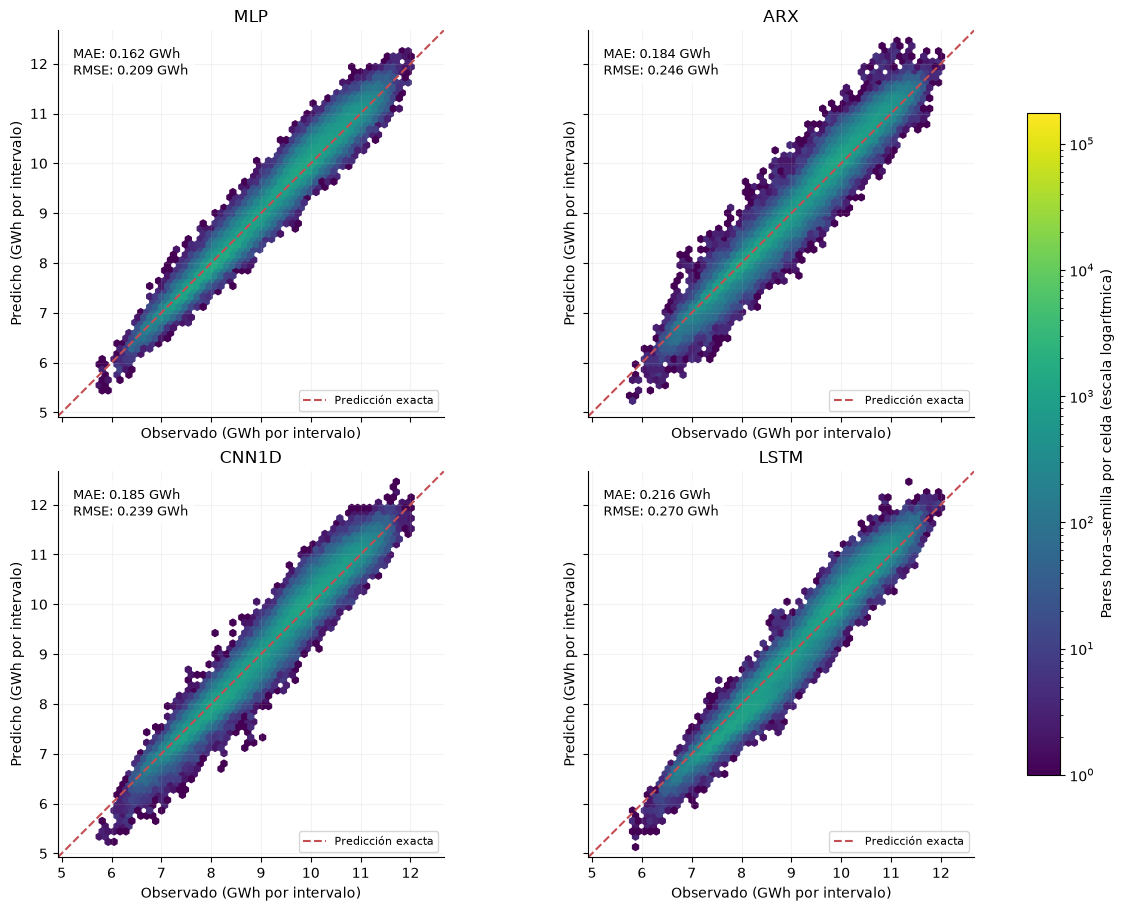

In [9]:
# Todas las horas y realizaciones individuales del benchmark.
observado_gwh = y.reshape(-1) / 1e6
observado_repetido = np.broadcast_to(y, pred[modelos[0]].shape).reshape(-1) / 1e6
extremos = [observado_gwh.min(), observado_gwh.max()]
for m in modelos:
    extremos.extend([pred[m].min() / 1e6, pred[m].max() / 1e6])
margen = 0.025 * (max(extremos) - min(extremos))
limites = (min(extremos) - margen, max(extremos) + margen)
resumen_visual = []
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True,
                         layout='constrained')
for ax, m in zip(axes.ravel(), modelos):
    assert pred[m].shape == (5, 1461, 24)
    errores_vis = pred[m] - y[None, :, :]
    mae_vis = float(np.abs(errores_vis).mean())
    rmse_vis = float(np.sqrt(np.mean(errores_vis**2, axis=(1, 2))).mean())
    esperado = benchmark.loc[benchmark.familia.eq(m)].iloc[0]
    assert np.isclose(mae_vis, esperado.MAE_kWh, rtol=1e-10)
    assert np.isclose(rmse_vis, esperado.RMSE_kWh, rtol=1e-10)
    densidad = ax.hexbin(observado_repetido, pred[m].reshape(-1) / 1e6,
                        gridsize=65, mincnt=1, bins='log', cmap='viridis',
                        extent=(*limites, *limites), vmin=1, vmax=len(observado_repetido))
    ax.plot(limites, limites, '--', color='#c44e52', lw=1.5,
            label='Predicción exacta')
    ax.set(title=etiquetas[m], xlim=limites, ylim=limites,
           xlabel='Observado (GWh por intervalo)',
           ylabel='Predicho (GWh por intervalo)')
    ax.set_aspect('equal', adjustable='box')
    ax.text(.04, .96, f'MAE: {mae_vis / 1e6:.3f} GWh\nRMSE: {rmse_vis / 1e6:.3f} GWh',
            transform=ax.transAxes, va='top', fontsize=9,
            bbox=dict(facecolor='white', alpha=.9, edgecolor='none'))
    ax.legend(loc='lower right', fontsize=8)
    resumen_visual.append(dict(modelo=m, horas_unicas=y.size, inicializaciones=5,
        pares_hora_semilla=errores_vis.size, MAE_kWh=mae_vis, RMSE_kWh=rmse_vis,
        sesgo_kWh=float(errores_vis.mean()),
        MAE_sobre_demanda_media_pct=100 * mae_vis / y.mean()))
fig.colorbar(densidad, ax=axes.ravel().tolist(), shrink=.8,
             label='Pares hora–semilla por celda (escala logarítmica)')
fig.savefig(OUT/'observado_vs_prediccion_2022_2025.png', dpi=170)
display(fig)
plt.close(fig)
resumen_visual = pd.DataFrame(resumen_visual)
resumen_visual.to_csv(OUT/'resumen_observado_predicho.csv', index=False)
destino_visual = ROOT/'book/_static/resultados/resumen_observado_predicho.csv'
destino_visual.parent.mkdir(parents=True, exist_ok=True)
resumen_visual.to_csv(destino_visual, index=False)
mejor_visual = resumen_visual.loc[resumen_visual.MAE_kWh.idxmin()]
mayor_visual = resumen_visual.loc[resumen_visual.MAE_kWh.idxmax()]
mae_visual_mlp = float(mejor_visual.MAE_kWh / 1e6)
ratio_visual_mlp = float(mejor_visual.MAE_sobre_demanda_media_pct)
mae_visual_lstm = float(mayor_visual.MAE_kWh / 1e6)


La MLP presenta el menor MAE agregado, 0.162 GWh por intervalo, equivalente al 1.77 % de la demanda media de prueba; esta razón contextualiza la escala del error y no es MAPE. La LSTM alcanza 0.216 GWh. La separación respecto de la diagonal permite localizar sobreestimaciones y subestimaciones que un error medio no distingue. La densidad reúne las cinco inicializaciones sobre las mismas horas; su número de pares no representa observaciones temporales independientes. [Resumen numérico de la figura](_static/resultados/resumen_observado_predicho.csv).

### Perfil horario en una semana de prueba

La ventana del 1 al 7 de julio de 2023 muestra la evolución intradiaria. La línea negra representa la demanda observada, la línea azul la media de los cinco pronósticos y la banda el rango p10–p90 entre inicializaciones. El MAE anotado promedia los errores individuales de esa semana, manteniendo el criterio de agregación del benchmark. La ventana ilustra picos y valles; no sustituye la evaluación del periodo completo.

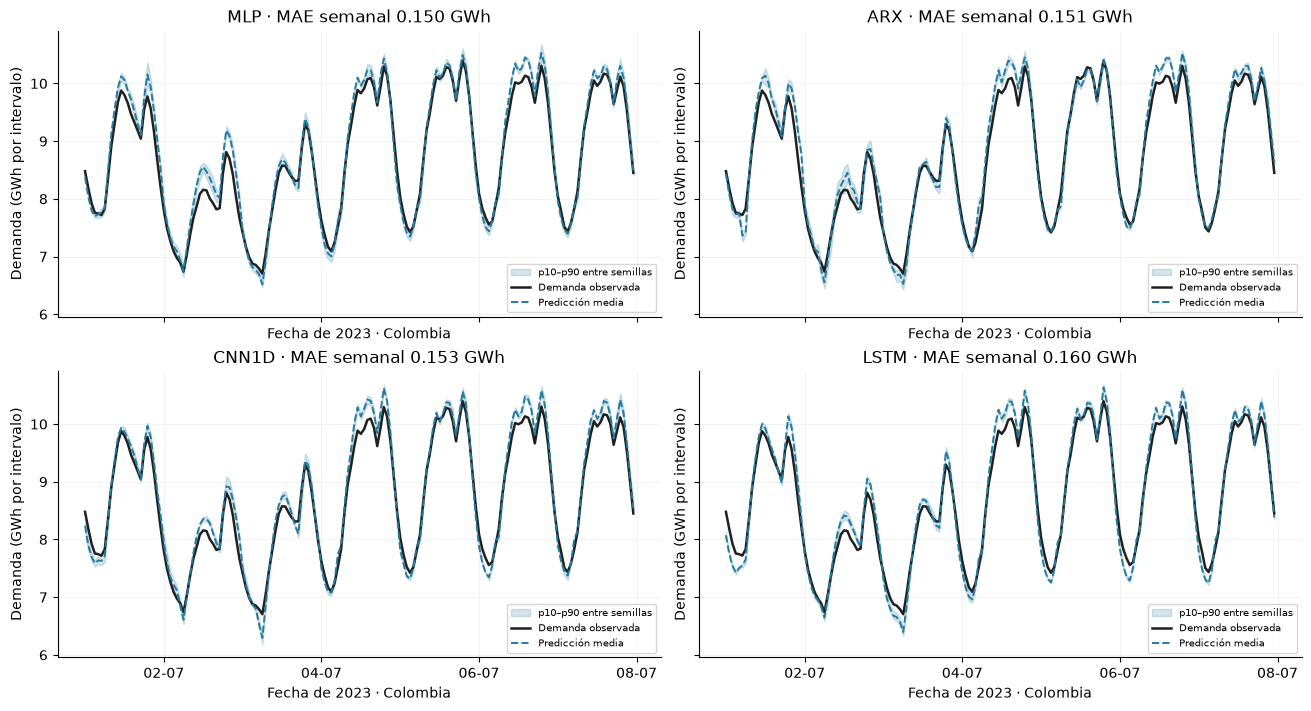

In [10]:
import matplotlib.dates as mdates
sel = ((fechas >= pd.Timestamp('2023-07-01', tz='America/Bogota')) &
       (fechas < pd.Timestamp('2023-07-08', tz='America/Bogota')))
assert sel.sum() == 7
tiempo = pd.DatetimeIndex([d + pd.Timedelta(hours=h)
                          for d in fechas[sel] for h in range(24)])
assert len(tiempo) == 168 and tiempo.is_unique and tiempo.is_monotonic_increasing
ventana_mae = {m: float(np.abs(pred[m][:, sel, :] - y[None, sel, :]).mean())
               for m in modelos}
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True,
                         layout='constrained')
for ax, m in zip(axes.ravel(), modelos):
    v = pred[m][:, sel, :].reshape(5, -1) / 1e6
    ax.fill_between(tiempo, np.quantile(v, .1, axis=0), np.quantile(v, .9, axis=0),
                    color='#247ba0', alpha=.2, label='p10–p90 entre semillas')
    ax.plot(tiempo, y[sel].reshape(-1) / 1e6, color='#202020', lw=1.8,
            label='Demanda observada')
    ax.plot(tiempo, v.mean(axis=0), color='#247ba0', lw=1.4, ls='--',
            label='Predicción media')
    ax.set(title=f'{etiquetas[m]} · MAE semanal {ventana_mae[m] / 1e6:.3f} GWh',
           ylabel='Demanda (GWh por intervalo)', xlabel='Fecha de 2023 · Colombia')
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=2, tz=tiempo.tz))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m', tz=tiempo.tz))
    ax.legend(fontsize=7, loc='lower right')
fig.savefig(OUT/'observado_vs_prediccion_semana.png', dpi=170)
display(fig)
plt.close(fig)
mejor_ventana = etiquetas[min(ventana_mae, key=ventana_mae.get)]
mae_mejor_ventana = min(ventana_mae.values()) / 1e6


MLP registra el menor MAE semanal, 0.150 GWh por intervalo. Las distancias entre las curvas permiten apreciar diferencias en amplitud, picos y valles que las métricas agregadas comprimen. Una banda estrecha indica acuerdo entre inicializaciones, sin garantizar proximidad al observado ni cobertura predictiva calibrada. La media de pronósticos se utiliza para visualizar el perfil; las métricas conservan los errores de cada realización.

## 10.8. Discusión crítica, alcance y margen disponible

La MLP establece el baseline empírico de estas configuraciones y obtiene el menor error agregado. Las t pareadas con Holm y los contrastes temporales detectan diferencias entre las tres redes en los datos evaluados; los contrastes por rangos no distinguen todas las parejas. ARX y CNN1D presentan medias próximas, sin una diferencia temporal significativa ni equivalencia demostrada por TOST. Los [resultados por método](10_evaluacion.ipynb) delimitan estas conclusiones.

La representación directa de rezagos y calendario de la MLP es coherente con los ciclos observados. La recurrencia de LSTM y los filtros compartidos de CNN1D no garantizan menor error: arquitectura, regularización, escalado y presupuesto intervienen conjuntamente. La generalización se evalúa por años, horas y tipos de día, además de las curvas de aprendizaje. El presupuesto desigual impide atribuir diferencias únicamente a la familia.

El margen de relevancia práctica es relativo: δ=3 %. La planificación aproximada exige más de cinco semillas para detectar ese margen con potencia del 80 %. Detectar diferencias observadas mayores no contradice esa limitación. La cronología de selección y la exposición al conjunto de prueba, documentadas en el capítulo 9, limitan la interpretación confirmatoria; los resultados son exploratorios.

La MLP contiene más parámetros que las otras redes, mientras LSTM requiere más tiempo en las condiciones registradas. El ajuste se ejecutó con PyTorch 2.9.1, ROCm 6.4 y GPU AMD de aproximadamente 12 GB. La latencia de inferencia se midió por separado en CPU; ambos tiempos describen procedimientos y dispositivos distintos. Los checkpoints, escaladores, historiales y predicciones se identifican mediante SHA-256 y el [pipeline completo](10_pipeline.md).

El ingenuo semanal constituye una referencia operativa, no una cota de ruido irreducible. Sin mediciones replicadas ni un modelo validado de error instrumental, esa cota no se identifica a partir de esta única serie; tampoco la determina el residuo del mejor modelo. Las mejoras publicadas en otros sistemas no son transferibles numéricamente al SIN. La siguiente etapa debe evaluar covariables y documentos disponibles al origen mediante ablaciones, presupuesto comparable y un protocolo prospectivo.

### Protocolo de medición de inferencia

Se cargan los 20 checkpoints sin modificar sus pesos. CPU, un hilo, batch uno, 20 pasadas de calentamiento y 200 mediciones por checkpoint. Se cronometra sólo forward con entradas sintéticas finitas de dimensiones operativas y 24 salidas; se excluyen carga, preparación, transferencia y escritura. Las medianas y p95 por familia agregan los valores de sus cinco checkpoints. [Entorno medido](_static/resultados/entorno_inferencia.json) y [mediciones por checkpoint](_static/resultados/latencia_inferencia.csv).

```python
"""Latencia CPU de checkpoints congelados, sin ajuste ni lectura de etiquetas."""
from pathlib import Path
from types import SimpleNamespace
import json,sys,time,platform,hashlib
import numpy as np
import pandas as pd
import torch

ROOT=Path(__file__).resolve().parents[1]
sha=json.loads((ROOT/'results/jbook/modelos_actualizados.json').read_text())['commit']
snapshot=ROOT/'results/repositorio'/sha
sys.path.insert(0,str(snapshot/'src'))
from demanda import modelos_base as M
from demanda.reentrenamiento_v3 import Secuencial as Convolucional
from demanda.variantes_v4 import Secuencial as Recurrente

def medir():
    torch.set_num_threads(1);torch.set_num_interop_threads(1)
    torch.manual_seed(11037)
    registro=json.loads((snapshot/'results/consolidado/modelos.json').read_text())
    entradas=SimpleNamespace(x=np.zeros((1,168,1),dtype=np.float32),
        cal_p=np.zeros((1,168,23),dtype=np.float32),cal_f=np.zeros((1,24,23),dtype=np.float32))
    x=torch.randn(1,168,24);c=torch.zeros(1,24,23)
    resultados=[]
    with torch.inference_mode():
        for nombre in ['mlp','arx_lineal','cnn1d','lstm']:
            for artefacto in sorted(registro[nombre]['artefactos'],key=lambda a:a['semilla']):
                path=snapshot/artefacto['pesos']
                checkpoint=torch.load(path,map_location='cpu',weights_only=True)
                p=registro[nombre]['configuracion']['params']
                if nombre=='lstm':red=Recurrente(nombre,p,entradas)
                elif nombre=='cnn1d':red=Convolucional(nombre,p,entradas)
                else:red=M.construir_red(nombre,p,entradas)
                red.load_state_dict(checkpoint['state_dict'],strict=True);red.eval()
                for _ in range(20):red(x,c)
                tiempos=[]
                for _ in range(200):
                    inicio=time.perf_counter_ns();salida=red(x,c);tiempos.append((time.perf_counter_ns()-inicio)/1e6)
                assert salida.shape==(1,24) and torch.isfinite(salida).all()
                resultados.append(dict(modelo=nombre,semilla=artefacto['semilla'],mediana_ms=float(np.median(tiempos)),p95_ms=float(np.quantile(tiempos,.95)),
                    media_ms=float(np.mean(tiempos)),repeticiones=200,calentamiento=20,batch=1,dispositivo='cpu',hilos=1,checkpoint_sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    out=ROOT/'results/jbook/modelos_actuales';out.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(resultados).to_csv(out/'latencia_inferencia.csv',index=False)
    entorno=dict(fecha=pd.Timestamp.now(tz='America/Bogota').isoformat(),python=sys.version,torch=torch.__version__,numpy=np.__version__,pandas=pd.__version__,
        sistema=platform.platform(),procesador=platform.processor(),dispositivo='cpu',hilos=1,commit=sha,
        alcance='Sólo forward de un origen con 24 salidas; entradas sintéticas finitas; sin carga de pesos, preparación, transferencia ni escritura en el intervalo medido',
        semillas=list(range(1000,1005)),calentamiento=20,repeticiones=200,nuevo_entrenamiento=False,etiquetas_leidas=False)
    (out/'entorno_inferencia.json').write_text(json.dumps(entorno,ensure_ascii=False,indent=2),encoding='utf-8')
    print(pd.DataFrame(resultados).groupby('modelo')[['mediana_ms','p95_ms']].median().round(4).to_string())

if __name__=='__main__':medir()

```